# Milestone 3 - Exploratory Data Analysis
Goal: describe **what, where, when and who** before testing or modelling anything. Each chart ends with a one-line
*"So what?"* for a manager. Figures are saved to `reports/figures/` and reused in the deck and dashboard.

In [1]:
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from config import PROCESSED, EXTERNAL, FIGURES, set_style, PALETTE, TEXT_2, kes
set_style()

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

sales = pd.read_pickle(PROCESSED / "sales_lines.pkl")
tx = pd.read_pickle(PROCESSED / "transactions.pkl")
stores = pd.read_csv(PROCESSED / "stores.csv", parse_dates=["open_date"])
customers = pd.read_csv(PROCESSED / "customers.csv", parse_dates=["signup_date"])
pop = pd.read_csv(EXTERNAL / "county_population_2019.csv")
tx["date"] = tx.transaction_datetime.dt.normalize()
tx["month"] = tx.transaction_datetime.dt.to_period("M")
tx = tx.merge(stores[["store_id", "county", "store_format", "store_name"]], on="store_id")
print(f"{len(sales):,} lines, {len(tx):,} receipts, {tx.customer_id.nunique():,} active members")

962,218 lines, 328,244 receipts, 5,536 active members


## 1. Headline KPIs

In [2]:
fy = lambda d: np.where(d >= pd.Timestamp("2025-10-01"), "Y2 (Oct25-Sep26)", "Y1 (Oct24-Sep25)")
tx["year_label"] = fy(tx.date)
sales["year_label"] = fy(sales.date)
kpi = tx.groupby("year_label").agg(revenue=("net_amount", "sum"), receipts=("transaction_id", "count"),
                                   avg_basket=("net_amount", "mean"), items_per_basket=("units", "mean"))
kpi["real_revenue"] = sales.groupby("year_label").net_amount_real.sum()
kpi.loc["growth %"] = (kpi.iloc[1] / kpi.iloc[0] - 1) * 100
kpi.round(1)

,revenue,receipts,avg_basket,items_per_basket,real_revenue
year_label,,,,,
Y1 (Oct24-Sep25),141331172.7,161215.0,876.7,4.0,139184760.9
Y2 (Oct25-Sep26),154831505.8,167029.0,927.0,4.0,145892695.8
growth %,9.6,3.6,5.7,0.0,4.8


**So what?** Nominal revenue grew, but part of that is price inflation - real (Oct-2024 shilling) growth is lower.
Growth comes from more receipts *and* bigger baskets.

## 2. Trend and seasonality - monthly revenue, nominal vs real

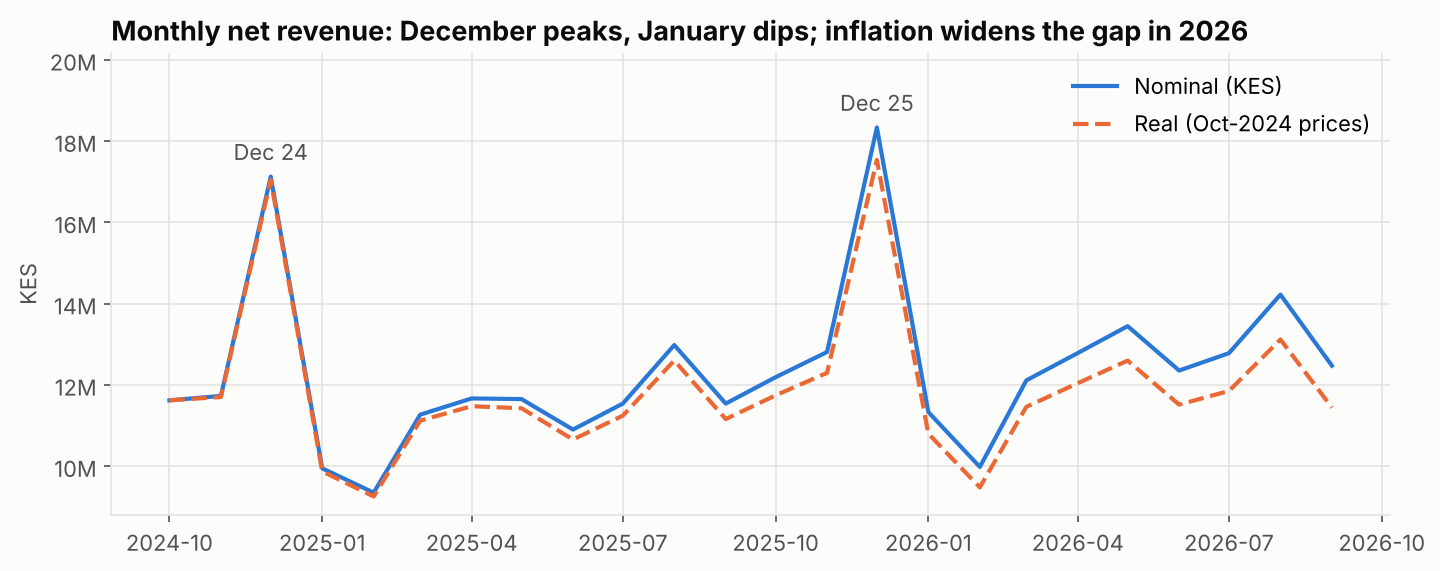

In [3]:
m = sales.groupby("month").agg(nominal=("net_amount", "sum"), real=("net_amount_real", "sum"))
fig, ax = plt.subplots(figsize=(11, 4))
x = m.index.to_timestamp()
ax.plot(x, m.nominal, label="Nominal (KES)", color=PALETTE[0])
ax.plot(x, m.real, label="Real (Oct-2024 prices)", color=PALETTE[1], linestyle="--")
ax.yaxis.set_major_formatter(mt.FuncFormatter(kes))
ax.set_ylabel("KES"); ax.set_title("Monthly net revenue: December peaks, January dips; inflation widens the gap in 2026")
ax.legend(loc="upper right")
ax.set_ylim(top=m.nominal.max() * 1.1)
for d, lbl in [("2024-12-01", "Dec 24"), ("2025-12-01", "Dec 25")]:
    ax.annotate(lbl, (pd.Timestamp(d), m.nominal[pd.Period(d[:7])]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=TEXT_2)
save(fig, "01_monthly_revenue")

**So what?** December is ~40% above an average month and January the weakest - stock and staff plans must flex
accordingly. From April 2026 inflation jumped (from ~4% to ~6.7%), so nominal growth flatters performance.

## 3. What sells - categories

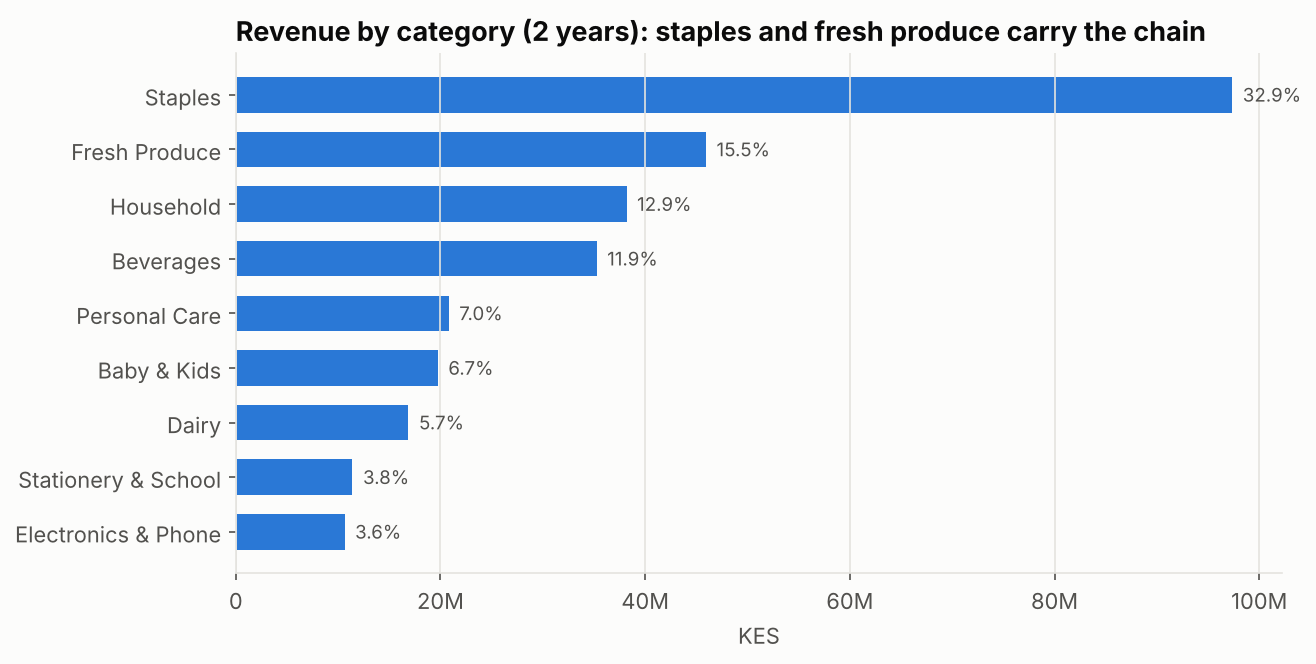

,revenue,units,share_%
category,,,
Staples,97360057.4,387188,32.9
Fresh Produce,45939914.6,299118,15.5
Household,38177523.2,115577,12.9
Beverages,35256439.8,187971,11.9
Personal Care,20800317.0,81156,7.0
Baby & Kids,19735035.0,27291,6.7
Dairy,16865470.1,147875,5.7
Stationery & School,11401297.5,36404,3.8
Electronics & Phone,10626624.0,32200,3.6


In [4]:
cat = sales.groupby("category").agg(revenue=("net_amount", "sum"), units=("quantity", "sum")).sort_values("revenue")
cat["share_%"] = 100 * cat.revenue / cat.revenue.sum()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(cat.index, cat.revenue, color=PALETTE[0], height=0.65)
for i, (v, s) in enumerate(zip(cat.revenue, cat["share_%"])):
    ax.text(v, i, f"  {s:.1f}%", va="center", color=TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(mt.FuncFormatter(kes))
ax.set_xlabel("KES"); ax.set_title("Revenue by category (2 years): staples and fresh produce carry the chain")
ax.grid(axis="y", visible=False)
save(fig, "02_category_revenue")
cat.sort_values("revenue", ascending=False).round(1)

## 4. Where - stores and counties

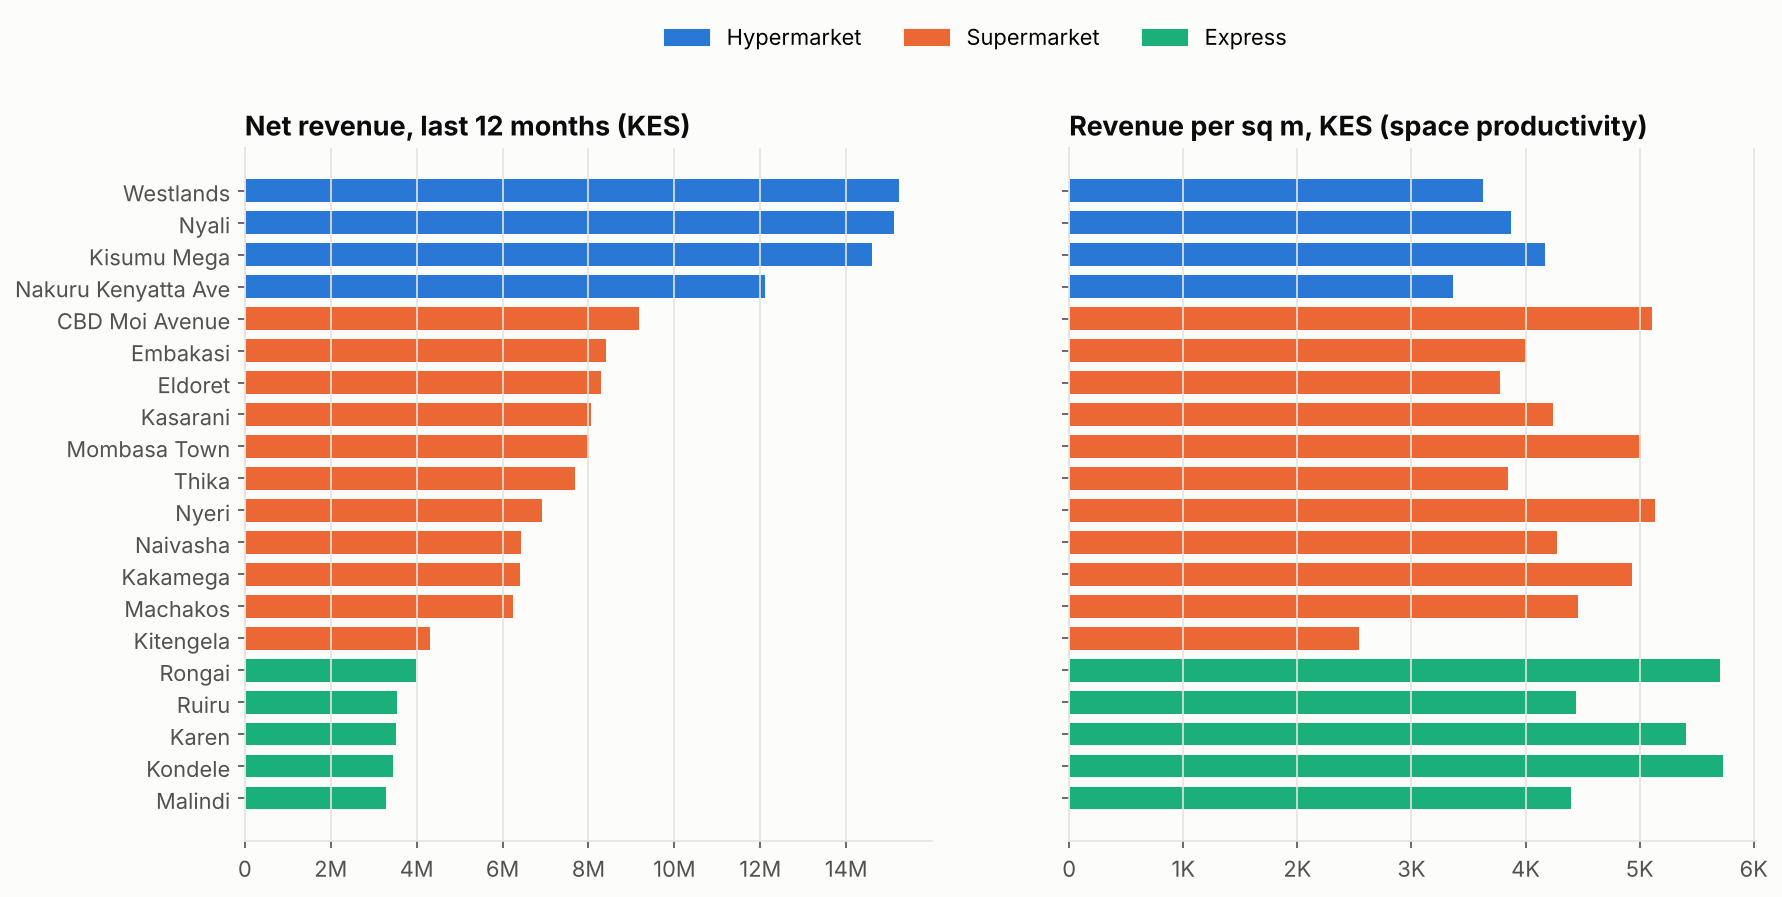

In [5]:
st = tx[tx.year_label.str.startswith("Y2")].groupby(["store_id", "store_name", "store_format"]).net_amount.sum().reset_index()
st = st.merge(stores[["store_id", "size_sqm"]], on="store_id").sort_values("net_amount")
st["rev_per_sqm"] = st.net_amount / st.size_sqm
fmt_color = {"Hypermarket": PALETTE[0], "Supermarket": PALETTE[1], "Express": PALETTE[2]}
fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
labels = st.store_name.str.replace("Mavuno Mart ", "")
ax[0].barh(labels, st.net_amount, color=st.store_format.map(fmt_color), height=0.7)
ax[0].xaxis.set_major_formatter(mt.FuncFormatter(kes)); ax[0].set_title("Net revenue, last 12 months (KES)")
ax[1].barh(labels, st.rev_per_sqm, color=st.store_format.map(fmt_color), height=0.7)
ax[1].set_title("Revenue per sq m, KES (space productivity)")
ax[1].xaxis.set_major_formatter(mt.FuncFormatter(kes))
for a in ax: a.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fmt_color.values()]
fig.legend(handles, fmt_color.keys(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
save(fig, "03_store_revenue")

**So what?** Hypermarkets earn the most in absolute terms, but **Express stores are the most productive per square metre** -
a strong argument for small-format expansion.

In [6]:
cty = tx[tx.year_label.str.startswith("Y2")].groupby("county").agg(revenue=("net_amount", "sum"),
                                                                    stores=("store_id", "nunique"))
cty = cty.join(pop.set_index("county"))
cty["rev_per_1000_residents"] = 1000 * cty.revenue / cty.population_2019
cty["rev_per_store"] = cty.revenue / cty.stores
print("Meru county (no store) population 2019:", f"{pop.set_index('county').population_2019['Meru']:,}")
cty.sort_values("revenue", ascending=False).round(0)

Meru county (no store) population 2019: 1,545,714


,revenue,stores,population_2019,rev_per_1000_residents,rev_per_store
county,,,,,
Nairobi,48403051.0,6,4397073,11008.0,8067175.0
Mombasa,23113052.0,2,1208333,19128.0,11556526.0
Nakuru,18526985.0,2,2162202,8569.0,9263492.0
Kisumu,18044215.0,2,1155574,15615.0,9022107.0
Kiambu,11246512.0,2,2417735,4652.0,5623256.0
Uasin Gishu,8301721.0,1,1163186,7137.0,8301721.0
Nyeri,6928365.0,1,759164,9126.0,6928365.0
Kakamega,6409045.0,1,1867579,3432.0,6409045.0
Machakos,6243791.0,1,1421932,4391.0,6243791.0


**So what?** Nairobi dominates revenue but penetration (revenue per resident) is highest in smaller single-store counties.
Meru (1.5M people) has no store at all - a candidate for expansion.

## 5. When - day of week, hour and payday

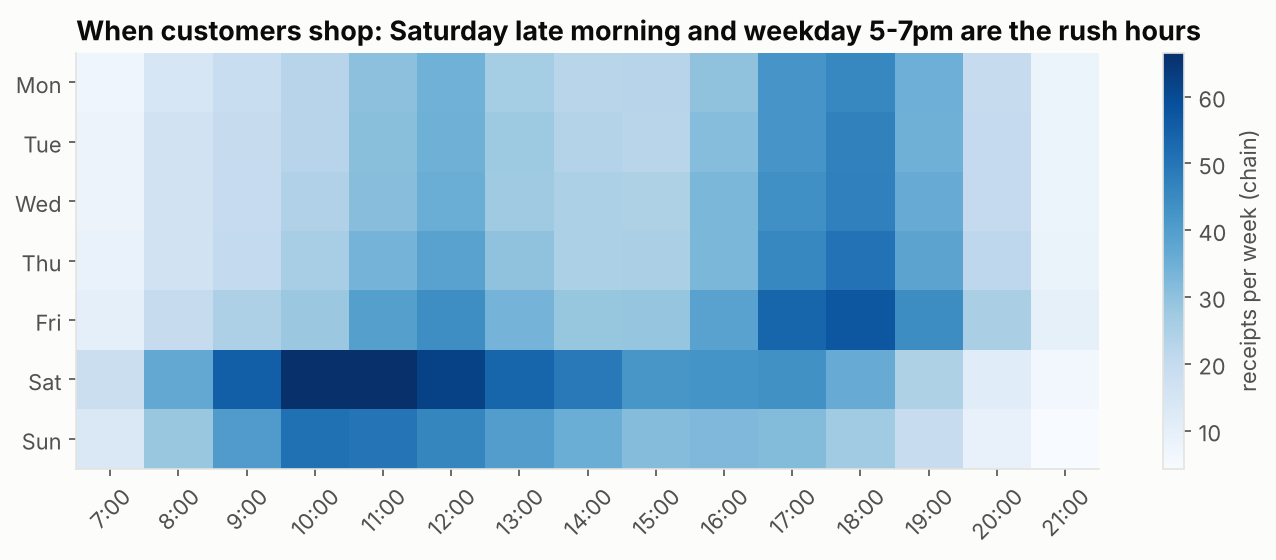

In [7]:
tx["dow"] = tx.transaction_datetime.dt.dayofweek
tx["hour"] = tx.transaction_datetime.dt.hour
heat = tx.pivot_table(index="dow", columns="hour", values="transaction_id", aggfunc="count") / tx.date.nunique() * 7
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(heat.shape[1]), [f"{h}:00" for h in heat.columns], rotation=45)
ax.grid(False)
fig.colorbar(im, ax=ax, label="receipts per week (chain)")
ax.set_title("When customers shop: Saturday late morning and weekday 5-7pm are the rush hours")
save(fig, "04_dow_hour_heatmap")

window
payday (25th-3rd)    483581.0
rest of month        370781.0
Name: rev, dtype: float64
payday lift: 30.4%


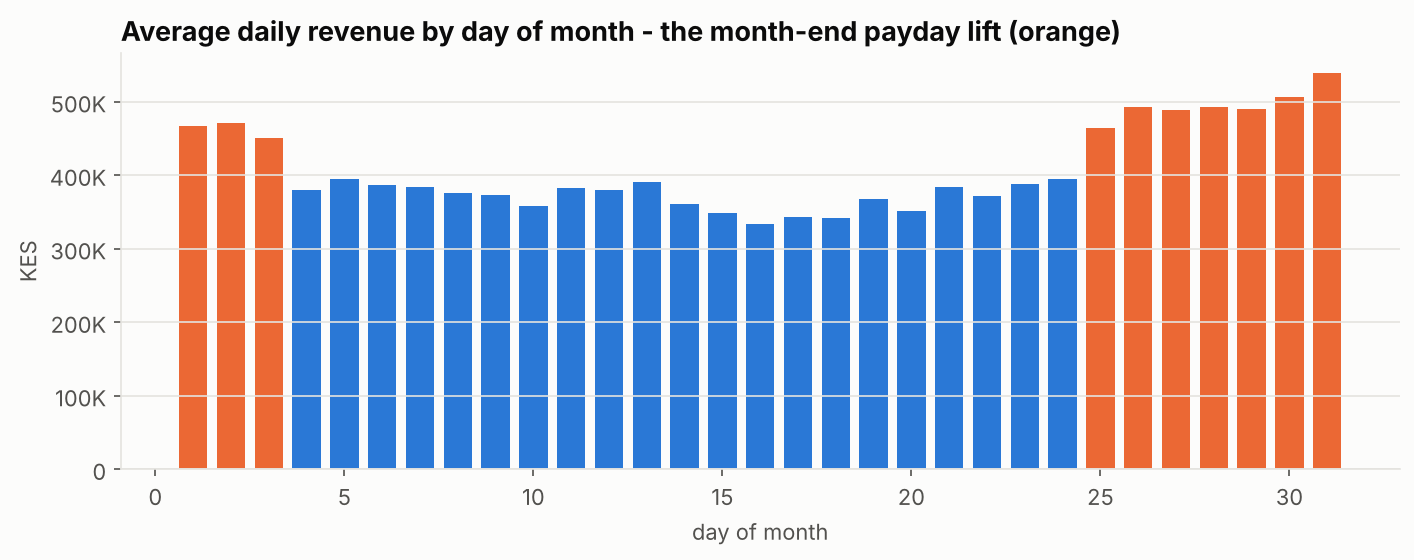

In [8]:
daily = tx.groupby("date").net_amount.sum().to_frame("rev")
daily["dom"] = daily.index.day
dom = daily.groupby("dom").rev.mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [PALETTE[1] if (d >= 25 or d <= 3) else PALETTE[0] for d in dom.index]
ax.bar(dom.index, dom.values, color=colors, width=0.75)
ax.yaxis.set_major_formatter(mt.FuncFormatter(kes))
ax.set(xlabel="day of month", ylabel="KES", title="Average daily revenue by day of month - the month-end payday lift (orange)")
ax.grid(axis="x", visible=False)
save(fig, "05_payday_effect")
pay = daily.assign(window=np.where((daily.dom >= 25) | (daily.dom <= 3), "payday (25th-3rd)", "rest of month")).groupby("window").rev.mean()
print(pay.round(0)); print(f"payday lift: {pay.iloc[0]/pay.iloc[1]-1:.1%}")

## 6. Category seasonality (index: month / category average)

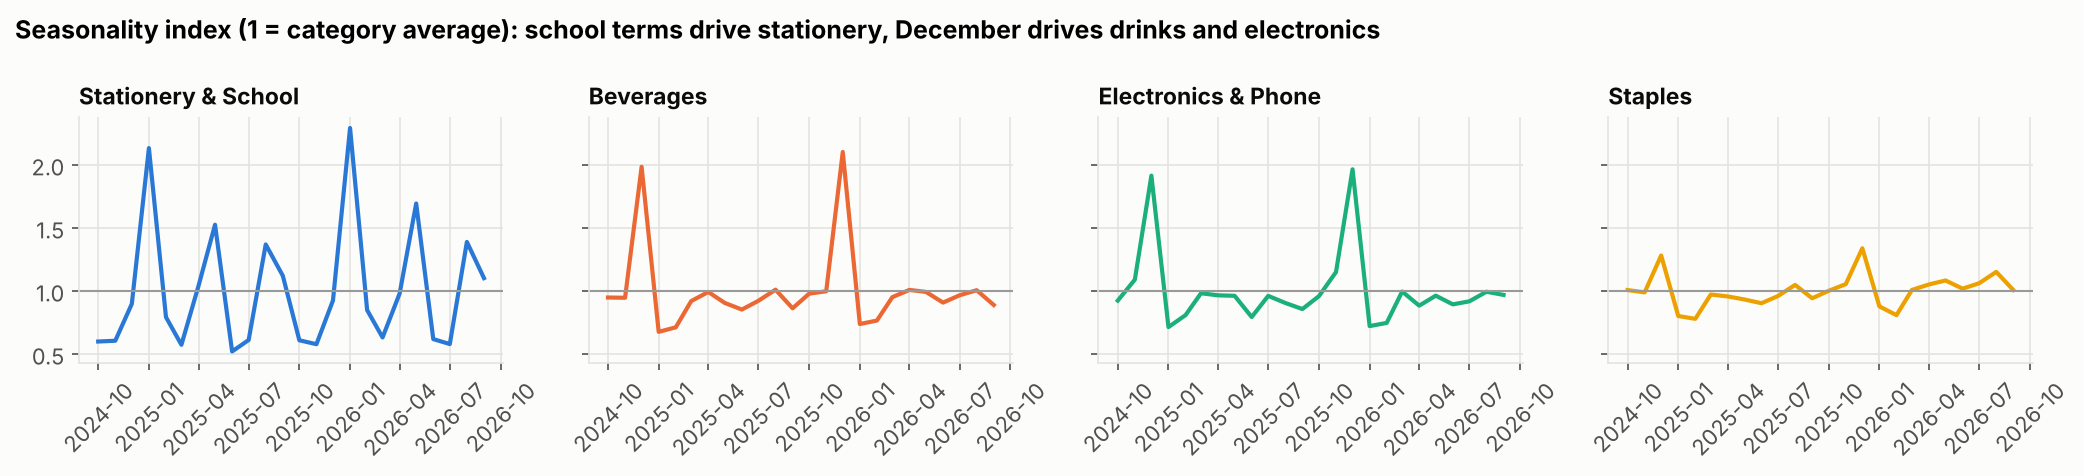

In [9]:
cm = sales.groupby(["month", "category"]).net_amount_real.sum().unstack()
idx = cm / cm.mean()
show = ["Stationery & School", "Beverages", "Electronics & Phone", "Staples"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, c, col in zip(axes, show, PALETTE):
    a.plot(idx.index.to_timestamp(), idx[c], color=col)
    a.axhline(1, color="#999", lw=1)
    a.set_title(c, fontsize=11)
    a.tick_params(axis="x", rotation=45)
fig.suptitle("Seasonality index (1 = category average): school terms drive stationery, December drives drinks and electronics",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "06_category_seasonality")

## 7. How they pay - M-Pesa

payment_method  Airtel Money  Card  Cash  M-Pesa
month                                           
2024-10                  2.7  13.5  28.3    55.5
2026-09                  3.0  14.3  23.1    59.6


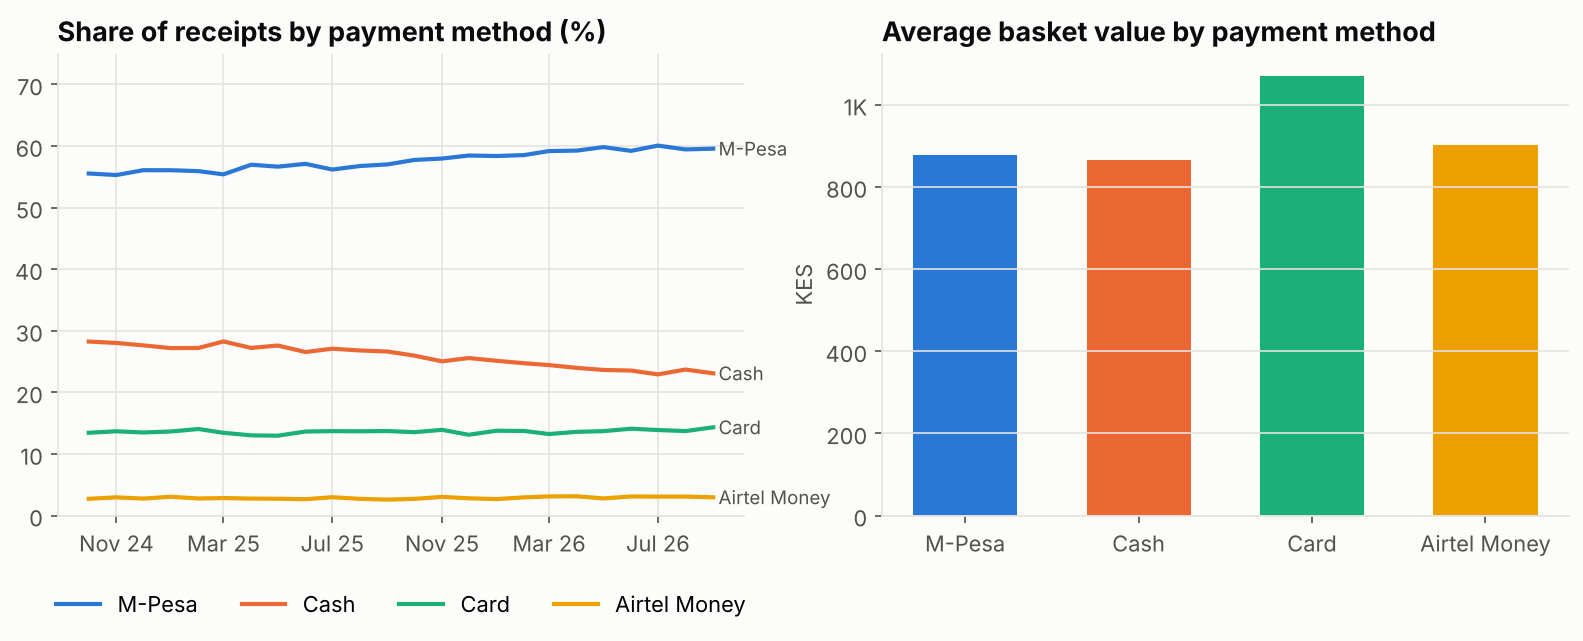

In [10]:
pm = tx[tx.payment_method != "Unknown"].groupby(["month", "payment_method"]).size().unstack()
share = pm.div(pm.sum(axis=1), axis=0) * 100
order = ["M-Pesa", "Cash", "Card", "Airtel Money"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c, col in zip(order, PALETTE):
    ax[0].plot(share.index.to_timestamp(), share[c], label=c, color=col)
    ax[0].text(share.index[-1].to_timestamp(), share[c].iloc[-1], f" {c}", va="center", color=TEXT_2, fontsize=9)
ax[0].set(title="Share of receipts by payment method (%)", ylim=(0, 75))
import matplotlib.dates as mdates
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=4)); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
basket = tx[tx.payment_method != "Unknown"].groupby("payment_method").net_amount.mean().reindex(order)
ax[1].bar(basket.index, basket.values, color=PALETTE[:4], width=0.6)
ax[1].yaxis.set_major_formatter(mt.FuncFormatter(kes))
ax[1].set_title("Average basket value by payment method"); ax[1].set_ylabel("KES")
ax[1].grid(axis="x", visible=False)
save(fig, "07_payment_methods")
print(share.iloc[[0, -1]].round(1))

**So what?** M-Pesa already handles the majority of receipts and is still gaining share from cash. Card baskets are the
largest. A Lipa na M-Pesa loyalty tie-in (e.g. points on Till payments) would reach most customers.

## 8. Who - members vs walk-ins, basket distribution

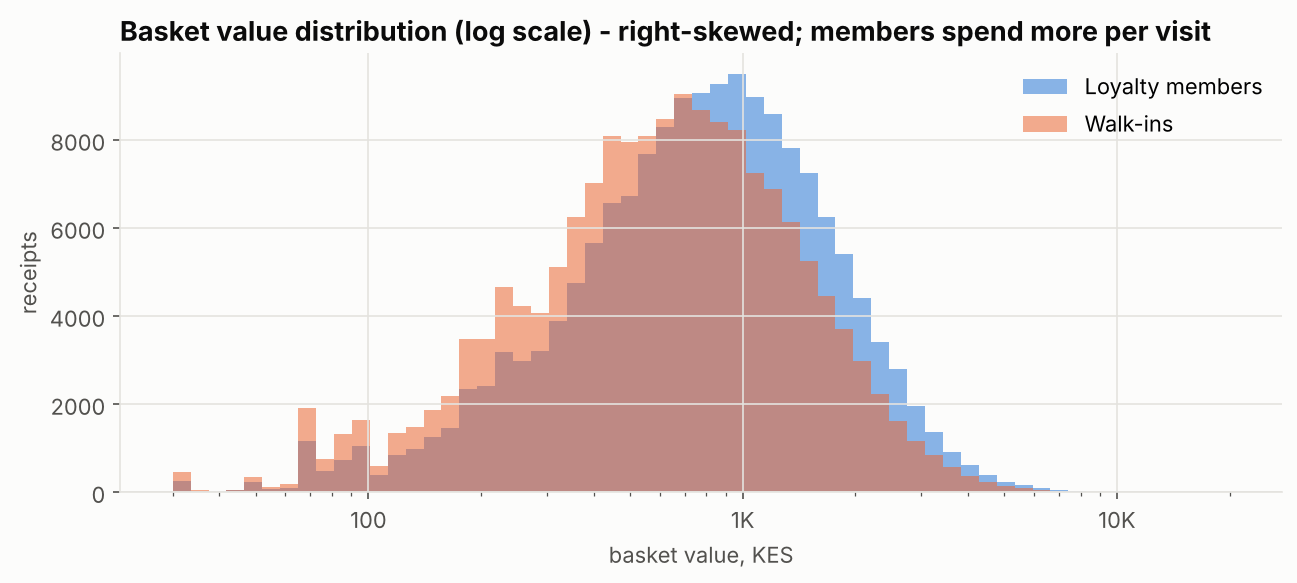

,count,mean,std,min,25%,50%,75%,max
is_member,,,,,,,,
False,163809.0,813.0,691.0,0.0,345.0,628.0,1065.0,8902.0
True,164435.0,992.0,787.0,0.0,450.0,791.0,1310.0,10859.0


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(np.log10(30), np.log10(20000), 60)
for lbl, col, mask in [("Loyalty members", PALETTE[0], tx.is_member), ("Walk-ins", PALETTE[1], ~tx.is_member)]:
    ax.hist(tx.net_amount[mask & (tx.net_amount > 0)], bins=bins, alpha=0.55, color=col, label=lbl)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mt.FuncFormatter(kes))
ax.set(xlabel="basket value, KES", title="Basket value distribution (log scale) - right-skewed; members spend more per visit", ylabel="receipts")
ax.legend()
save(fig, "08_basket_distribution")
tx.groupby("is_member").net_amount.describe().round(0)

In [12]:
mem = tx[tx.is_member].groupby("customer_id").agg(spend=("net_amount", "sum"), visits=("transaction_id", "count"))
mem = mem.join(customers.set_index("customer_id")[["age_band", "gender"]])
mem.groupby("age_band").agg(customers=("spend", "size"), avg_spend=("spend", "mean"), avg_visits=("visits", "mean")).round(0)

,customers,avg_spend,avg_visits
age_band,,,
18-24,483,26657.0,27.0
25-34,1539,30252.0,31.0
35-44,2005,28502.0,29.0
45-54,1169,30110.0,30.0
55+,284,32958.0,32.0
Unknown,56,34254.0,34.0


In [13]:
# Pareto: what share of member revenue comes from the top 20% of members?
s = mem.spend.sort_values(ascending=False)
top20 = s.iloc[: int(len(s) * 0.2)].sum() / s.sum()
print(f"Top 20% of members generate {top20:.0%} of member revenue")

Top 20% of members generate 64% of member revenue


## 9. Anomalies worth investigating - Nakuru and the new Kitengela store

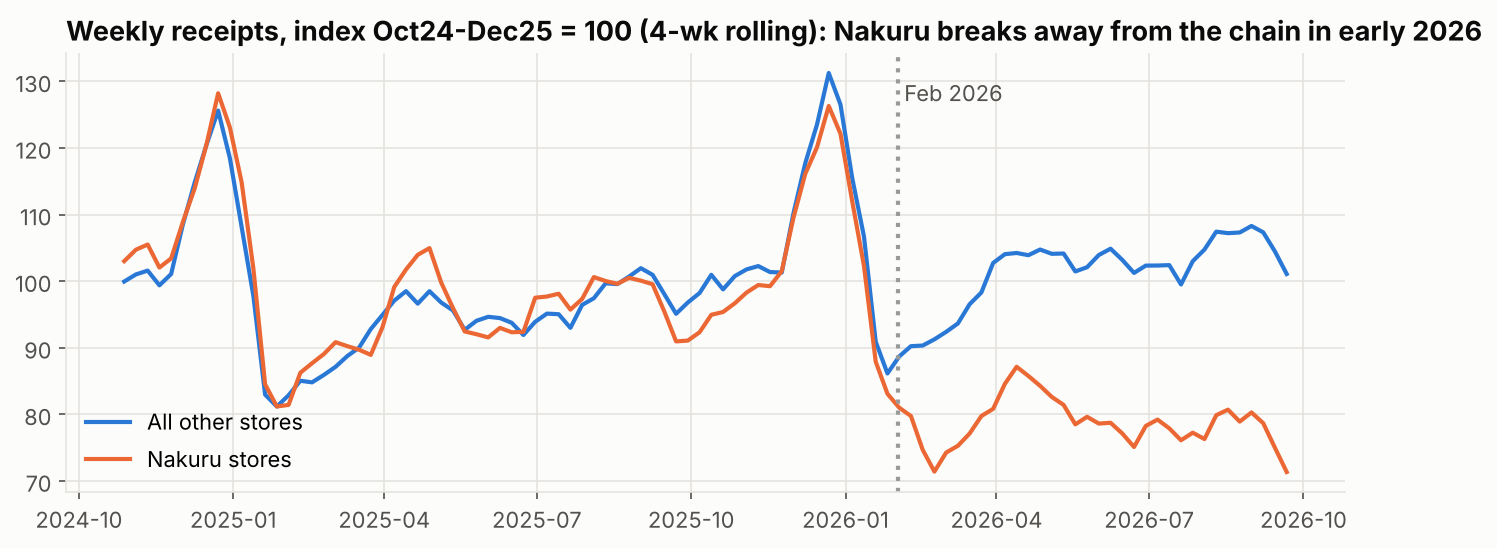

In [14]:
wk = tx.assign(week=tx.date.dt.to_period("W").dt.start_time)
grp = np.where(wk.county == "Nakuru", "Nakuru stores", "All other stores")
w = wk.groupby(["week", grp]).transaction_id.count().unstack()
w = w / w.loc[: "2025-12-31"].mean() * 100      # index: Oct24-Dec25 average = 100
w = w.iloc[1:-1].rolling(4).mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(w.index, w["All other stores"], color=PALETTE[0], label="All other stores")
ax.plot(w.index, w["Nakuru stores"], color=PALETTE[1], label="Nakuru stores")
ax.axvline(pd.Timestamp("2026-02-01"), color="#999", ls=":")
ax.text(pd.Timestamp("2026-02-05"), ax.get_ylim()[1] * 0.97, "Feb 2026", color=TEXT_2, va="top")
ax.set_title("Weekly receipts, index Oct24-Dec25 = 100 (4-wk rolling): Nakuru breaks away from the chain in early 2026")
ax.legend(loc="lower left")
save(fig, "09_nakuru_anomaly")

**So what?** Nakuru traffic falls ~20% below the rest of the chain from February 2026 - consistent with a new competitor
(confirmed by the area manager in the business narrative). This feeds the churn analysis (Milestone 6) and the dashboard.

In [15]:
k = tx[tx.store_id == "S020"].groupby("month").agg(revenue=("net_amount", "sum"), receipts=("transaction_id", "count"))
k.T.round(0)

month,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
revenue,35857.0,86803.0,138539.0,195869.0,295352.0,343878.0,487592.0,302698.0,253892.0,322352.0,371331.0,377453.0,364088.0,383755.0,397683.0,417852.0
receipts,52.0,113.0,172.0,247.0,371.0,415.0,515.0,377.0,338.0,399.0,443.0,424.0,444.0,442.0,468.0,446.0


## 10. EDA summary
1. **Seasonality is strong and predictable**: December ~+40%, January lowest, Saturday and month-end paydays busiest,
   stationery spikes at the three school-term starts. -> forecasting features.
2. **Revenue concentration**: staples + fresh produce + dairy are the majority of sales; a few hypermarkets carry absolute
   revenue, but Express stores are the most space-efficient.
3. **M-Pesa dominates and is rising**; cash falling.
4. **Members spend more per visit than walk-ins**, and the top 20% of members bring a disproportionate share.
5. **Inflation** explains a meaningful slice of nominal growth in 2026.
6. **Nakuru** shows a structural traffic drop from Feb 2026.